<a href="https://colab.research.google.com/github/ivansuarez-AU/MAI510_M2_Assignment_2_1/blob/main/MAI510_M2_Assignment_2_1_Student_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 510 | Module 2 | Assignment 2.1
## Build, train, evaluate and explain a clothing classifier
**Atlantis University | Google Colab lab**

**Learning goal:** Train a convolutional network on Fashion-MNIST, identify overfitting, evaluate all ten classes, investigate four real mistakes, and export a student-named evidence package.

**Instructor:** In the first run, select `DEMO_MODE = True` for a short demonstration. Students should select `False` for their full assignment and justify the stopping rule.

**Source alignment:** This notebook implements the supplied Assignment 2.1 instructions. The original reference-project code was not supplied, so this is a documented teaching implementation—not a verified exact copy of `Build_Clothing_Prediction_Flask_Web_App`.

### LAB 0 — Register yourself
Run the following cell and **type your full name** when prompted. Do not type into the code itself. All exported files will include your name.

In [1]:
import os, re, json, random, zipfile, shutil
from pathlib import Path
STUDENT_NAME = input("Enter your FULL name for reports: ").strip()
while len(STUDENT_NAME.split()) < 2:
    print("Please enter your first and last name (example: Maria Rodriguez).")
    STUDENT_NAME = input("Enter your FULL name: ").strip()
SAFE_NAME = re.sub(r"[^A-Za-z0-9]+", "_", STUDENT_NAME).strip("_")
COURSE = "MAI 510 - Deep Learning"
ASSIGNMENT = "Module 2 - Assignment 2.1"
OUT = Path(f"MAI510_M2_A21_{SAFE_NAME}")
OUT.mkdir(exist_ok=True)
print(f"Welcome, {STUDENT_NAME}. Your files will appear in {OUT}/")

Enter your FULL name for reports: Ivan Suarez
Welcome, Ivan Suarez. Your files will appear in MAI510_M2_A21_Ivan_Suarez/


### LAB 1 — Settings and reproducibility
For the classroom demonstration set `DEMO_MODE=True` to train quickly. For the graded experiment use `False` and record the epoch budget and early-stopping rule.

In [2]:
DEMO_MODE = True   # Students: change to False for a longer, defensible experiment
SEED = 42
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from IPython.display import display
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| Demo mode:', DEMO_MODE)
EPOCH_LIMIT = 4 if DEMO_MODE else 25
PATIENCE = 2 if DEMO_MODE else 4
BATCH_SIZE = 128

TensorFlow: 2.21.0 | Demo mode: True


### LAB 2 — Load Fashion-MNIST and inspect the shapes
Fashion-MNIST supplies **60,000 training images and 10,000 test images**, each **28×28 grayscale pixels**. We will hold out part of the training set for validation. Do not use the test set to choose the stopping epoch.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training: (60000, 28, 28) Test: (10000, 28, 28)


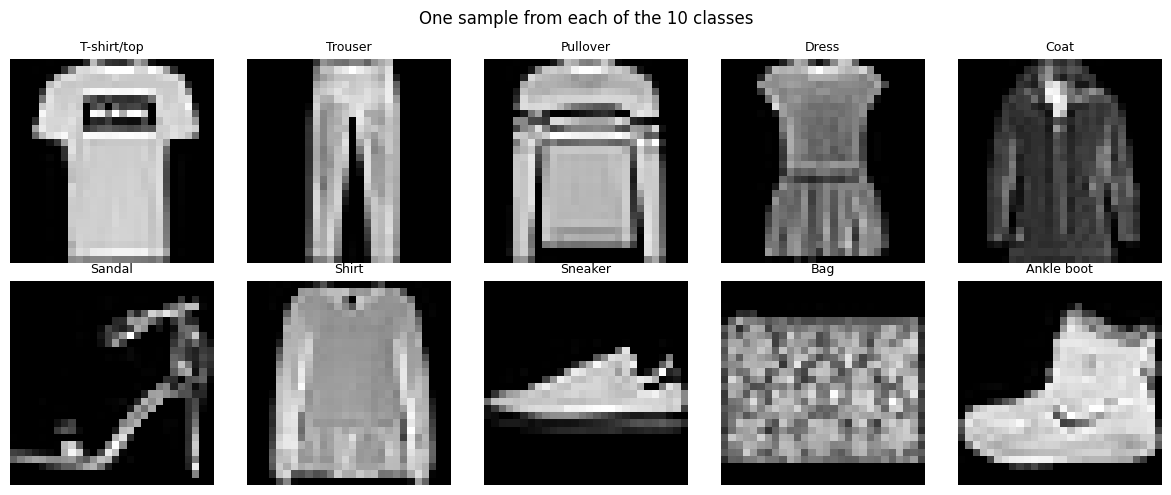

In [3]:
CLASS_NAMES = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
(x_train_full, y_train_full), (x_test_raw, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print('Training:', x_train_full.shape, 'Test:', x_test_raw.shape)
fig,axes=plt.subplots(2,5,figsize=(12,5))
for ax,k in zip(axes.flat,range(10)):
    idx=int(np.where(y_train_full==k)[0][0]);ax.imshow(x_train_full[idx],cmap='gray')
    ax.set_title(CLASS_NAMES[k],fontsize=9);ax.axis('off')
fig.suptitle('One sample from each of the 10 classes');plt.tight_layout()
plt.savefig(OUT/'01_class_examples.png',dpi=160,bbox_inches='tight');plt.show()

**Discuss:** What visual evidence separates a sandal from a sneaker? Why might a shirt and T-shirt/top be difficult?

### LAB 3 — Normalize, reshape, split and encode
Rescale pixels from 0–255 to 0–1. Add the channel axis for a CNN. Use one-hot label encoding with `categorical_crossentropy` (consistent pairing). Preserve a held-out **10,000-image validation set**, separated from the 10,000-image test set.

In [4]:
x_train = x_train_full[:50000].astype('float32') / 255.0
x_val   = x_train_full[50000:].astype('float32') / 255.0
x_test  = x_test_raw.astype('float32') / 255.0
x_train=x_train[...,np.newaxis];x_val=x_val[...,np.newaxis];x_test=x_test[...,np.newaxis]
y_train=tf.keras.utils.to_categorical(y_train_full[:50000],10)
y_val=tf.keras.utils.to_categorical(y_train_full[50000:],10)
y_test_oh=tf.keras.utils.to_categorical(y_test,10)
print('Train/val/test:',x_train.shape,x_val.shape,x_test.shape)
print('Pixel range:',x_train.min(),x_train.max(),'One-hot example:',y_train[0])

Train/val/test: (50000, 28, 28, 1) (10000, 28, 28, 1) (10000, 28, 28, 1)
Pixel range: 0.0 1.0 One-hot example: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


### LAB 4 — Inspect the convolutional network
Our teaching CNN uses two convolution blocks, max pooling, batch normalization, dropout and a 10-way softmax. **Do not claim this is an exact reproduction of the unavailable reference code.** The baseline uses the same architecture throughout Assignment 2.1.

In [5]:
def make_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28,28,1)),
        tf.keras.layers.Conv2D(32, (3,3), padding='same', activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.30),
        tf.keras.layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model
model = make_model()
model.summary()
print('Total parameters:',model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,618 (861.79 KB)

 Trainable params: 220,426 (861.04 KB)

 Non-trainable params: 192 (768.00 B)

Total parameters: 220618


**Pause and predict:** Which layer detects local edges? Which layer reduces spatial resolution? What is the role of softmax?

### LAB 5 — Train, with validation-based early stopping
Early stopping monitors **validation loss**, restores the best weights, and avoids choosing a model solely because training accuracy increased. The resulting history remains available for overfitting analysis.

In [6]:
callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=PATIENCE,
                                                   restore_best_weights=True,min_delta=0.001)
history = model.fit(x_train,y_train,validation_data=(x_val,y_val),
                    epochs=EPOCH_LIMIT,batch_size=BATCH_SIZE,verbose=2,
                    callbacks=[callback])
hist = pd.DataFrame(history.history)
hist.insert(0,'epoch',np.arange(1,len(hist)+1))
hist.to_csv(OUT/'02_training_history.csv',index=False)
BEST_EPOCH=int(hist.loc[hist['val_loss'].idxmin(),'epoch'])
print('Epochs executed:',len(hist),'Best validation-loss epoch:',BEST_EPOCH)
print(hist.to_string(index=False))

Epoch 1/4
391/391 - 73s - 185ms/step - accuracy: 0.8179 - loss: 0.5209 - val_accuracy: 0.7018 - val_loss: 0.9290
Epoch 2/4
391/391 - 82s - 209ms/step - accuracy: 0.8782 - loss: 0.3369 - val_accuracy: 0.8934 - val_loss: 0.2839
Epoch 3/4
391/391 - 71s - 181ms/step - accuracy: 0.8950 - loss: 0.2878 - val_accuracy: 0.8950 - val_loss: 0.2751
Epoch 4/4
391/391 - 68s - 175ms/step - accuracy: 0.9067 - loss: 0.2565 - val_accuracy: 0.8984 - val_loss: 0.2694
Epochs executed: 4 Best validation-loss epoch: 4
 epoch  accuracy     loss  val_accuracy  val_loss
     1   0.81786 0.520890        0.7018  0.928996
     2   0.87822 0.336903        0.8934  0.283949
     3   0.89496 0.287832        0.8950  0.275110
     4   0.90666 0.256451        0.8984  0.269353


### LAB 6 — Plot accuracy and loss, annotate overfitting
A possible warning sign is that training loss keeps decreasing while validation loss increases. The lowest validation-loss epoch is **not automatically proof that overfitting began there**. Inspect the trends, and if the evidence is inconclusive, report that honestly.

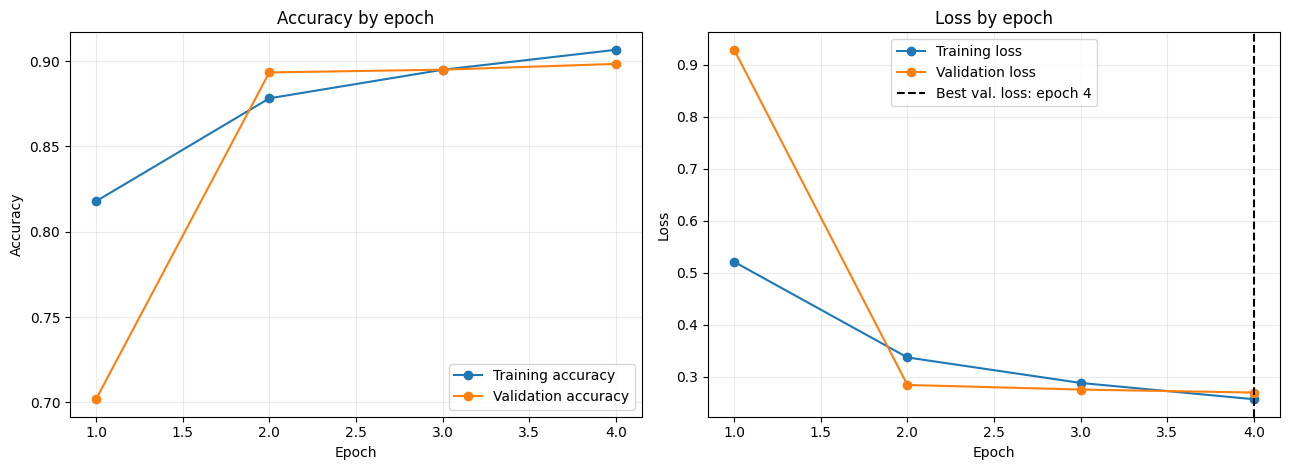

First candidate divergence epoch: None
CAUTION: Inspect subsequent epochs before concluding overfitting occurred.


In [7]:
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
ax[0].plot(hist.epoch,hist.accuracy,marker='o',label='Training accuracy')
ax[0].plot(hist.epoch,hist.val_accuracy,marker='o',label='Validation accuracy')
ax[0].set(title='Accuracy by epoch',xlabel='Epoch',ylabel='Accuracy');ax[0].legend();ax[0].grid(alpha=.25)
ax[1].plot(hist.epoch,hist.loss,marker='o',label='Training loss')
ax[1].plot(hist.epoch,hist.val_loss,marker='o',label='Validation loss')
ax[1].axvline(BEST_EPOCH,color='black',linestyle='--',label=f'Best val. loss: epoch {BEST_EPOCH}')
ax[1].set(title='Loss by epoch',xlabel='Epoch',ylabel='Loss');ax[1].legend();ax[1].grid(alpha=.25)
plt.tight_layout();plt.savefig(OUT/'03_training_validation_curves.png',dpi=180,bbox_inches='tight');plt.show()
OVERFIT_EPOCH = None
for i in range(1,len(hist)):
    if hist.loc[i,'val_loss'] > hist.loc[i-1,'val_loss'] and hist.loc[i,'loss'] < hist.loc[i-1,'loss']:
        OVERFIT_EPOCH=int(hist.loc[i,'epoch']);break
print('First candidate divergence epoch:', OVERFIT_EPOCH)
print('CAUTION: Inspect subsequent epochs before concluding overfitting occurred.')

**Student response:** Did overfitting clearly occur? If yes, cite the epoch and both curves. If not, explain why no firm claim can be made. In demo mode the short run often will not establish overfitting.

### LAB 7 — Evaluate on the untouched test set
Test accuracy must be distinguished from training and validation accuracy.

In [8]:
test_loss,test_acc=model.evaluate(x_test,y_test_oh,verbose=0)
probs=model.predict(x_test,batch_size=256,verbose=0)
y_pred=probs.argmax(axis=1)
print(f'Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}')
print(classification_report(y_test,y_pred,target_names=CLASS_NAMES,digits=3))
model.save(OUT/f'{SAFE_NAME}_fashion_cnn.keras')
with open(OUT/'04_metrics.json','w') as f:
    json.dump({'student':STUDENT_NAME,'demo_mode':DEMO_MODE,'epochs_completed':int(len(hist)),
               'best_val_loss_epoch':BEST_EPOCH,'candidate_divergence_epoch':OVERFIT_EPOCH,
               'test_accuracy':float(test_acc),'test_loss':float(test_loss),
               'train_images':len(x_train),'validation_images':len(x_val),'test_images':len(x_test)},f,indent=2)
print('Saved model and metrics.')

Test accuracy: 0.8899 | Test loss: 0.2924
              precision    recall  f1-score   support

 T-shirt/top      0.845     0.845     0.845      1000
     Trouser      0.999     0.957     0.978      1000
    Pullover      0.916     0.765     0.834      1000
       Dress      0.897     0.893     0.895      1000
        Coat      0.866     0.791     0.827      1000
      Sandal      0.953     0.989     0.971      1000
       Shirt      0.612     0.796     0.692      1000
     Sneaker      0.932     0.965     0.948      1000
         Bag      0.985     0.978     0.981      1000
  Ankle boot      0.988     0.920     0.953      1000

    accuracy                          0.890     10000
   macro avg      0.899     0.890     0.892     10000
weighted avg      0.899     0.890     0.892     10000

Saved model and metrics.


### LAB 8 — Full 10×10 confusion matrix
Rows are actual classes; columns are predicted classes. Entries on the diagonal represent correct predictions.

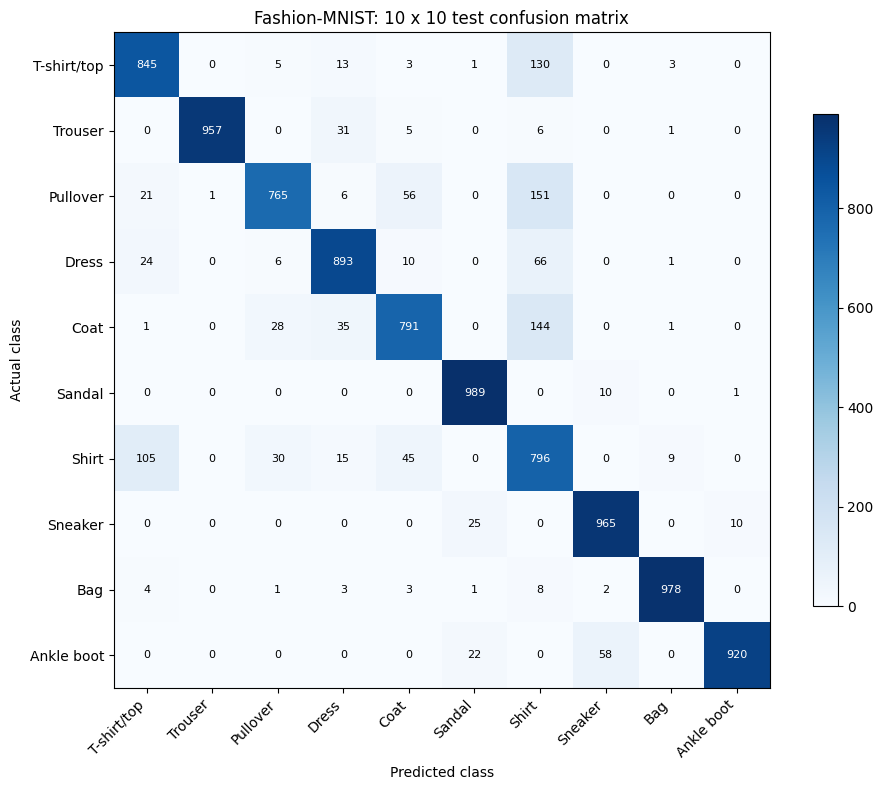

In [9]:
cm=confusion_matrix(y_test,y_pred,labels=np.arange(10))
pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(OUT/'05_confusion_matrix.csv')
fig,ax=plt.subplots(figsize=(10,8));im=ax.imshow(cm,cmap='Blues')
ax.set_xticks(range(10),CLASS_NAMES,rotation=45,ha='right');ax.set_yticks(range(10),CLASS_NAMES)
ax.set(xlabel='Predicted class',ylabel='Actual class',title='Fashion-MNIST: 10 x 10 test confusion matrix')
for i in range(10):
    for j in range(10): ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,color='white' if cm[i,j]>cm.max()/2 else 'black')
fig.colorbar(im,ax=ax,shrink=.75);plt.tight_layout()
plt.savefig(OUT/'06_confusion_matrix.png',dpi=180,bbox_inches='tight');plt.show()

### LAB 9 — Find the most frequently confused *pair* of distinct classes
We define pair confusion as the **sum of mistakes in both directions**, `actual A → predicted B` plus `actual B → predicted A`. This is different from the single largest off-diagonal cell; we print both for transparency.

In [10]:
pair_scores=[(int(cm[a,b]+cm[b,a]),a,b) for a in range(10) for b in range(a+1,10)]
pair_scores.sort(reverse=True)
PAIR_TOTAL,A,B=pair_scores[0]
cm_without_diag=cm.copy();np.fill_diagonal(cm_without_diag,0)
single_a,single_b=np.unravel_index(cm_without_diag.argmax(),cm_without_diag.shape)
print(f'Most confused pair: {CLASS_NAMES[A]} <-> {CLASS_NAMES[B]} | total mistakes: {PAIR_TOTAL}')
print(f'  {CLASS_NAMES[A]} -> {CLASS_NAMES[B]}: {cm[A,B]}')
print(f'  {CLASS_NAMES[B]} -> {CLASS_NAMES[A]}: {cm[B,A]}')
print(f'Largest single-direction error: {CLASS_NAMES[single_a]} -> {CLASS_NAMES[single_b]} ({cm[single_a,single_b]})')

Most confused pair: T-shirt/top <-> Shirt | total mistakes: 235
  T-shirt/top -> Shirt: 130
  Shirt -> T-shirt/top: 105
Largest single-direction error: Pullover -> Shirt (151)


### LAB 10 — Display four misclassified images for the confused pair
We include examples from both directions where available; otherwise all available examples for the pair. If there are fewer than four, the notebook displays what exists and prompts the student to disclose that limitation (rare with standard Fashion-MNIST training).

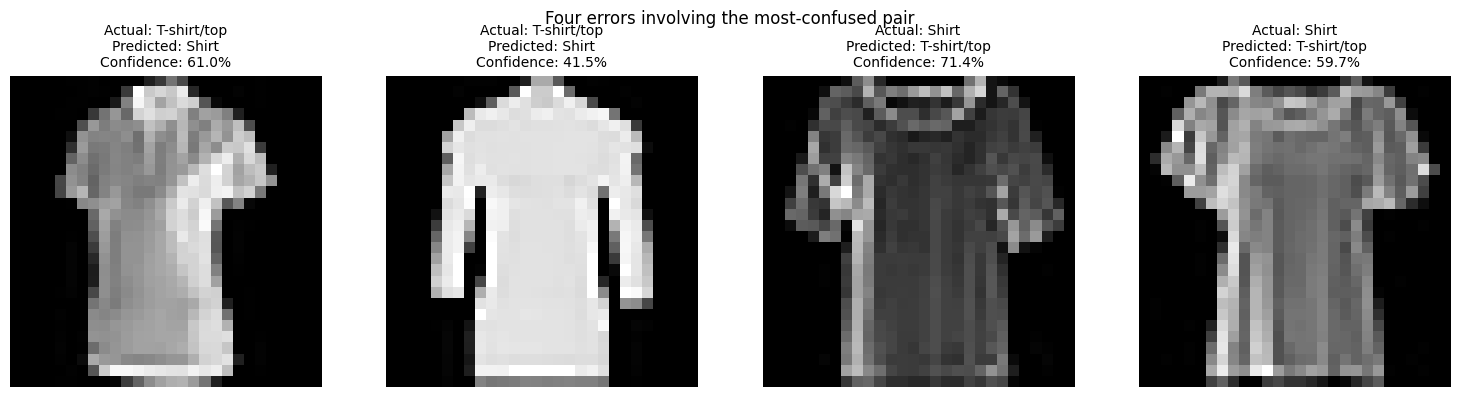

In [11]:
a_to_b=np.where((y_test==A)&(y_pred==B))[0].tolist()
b_to_a=np.where((y_test==B)&(y_pred==A))[0].tolist()
selected=a_to_b[:2]+b_to_a[:2]
for index in a_to_b[2:]+b_to_a[2:]:
    if len(selected)>=4:break
    selected.append(index)
if len(selected)<4: print('Only',len(selected),'pair-confusion examples available; disclose this in report.')
rows=[]; fig, axes=plt.subplots(1,max(1,len(selected)),figsize=(3.8*max(1,len(selected)),4))
axes=np.atleast_1d(axes)
for ax,index in zip(axes,selected):
    actual=int(y_test[index]);pred=int(y_pred[index]);confidence=float(probs[index,pred]);
    ax.imshow(x_test[index,:,:,0],cmap='gray');ax.axis('off')
    ax.set_title(f'Actual: {CLASS_NAMES[actual]}\nPredicted: {CLASS_NAMES[pred]}\nConfidence: {confidence:.1%}',fontsize=10)
    rows.append({'image_index':int(index),'actual':CLASS_NAMES[actual],
                 'predicted':CLASS_NAMES[pred],'confidence':confidence})
plt.suptitle('Four errors involving the most-confused pair');plt.tight_layout()
plt.savefig(OUT/'07_four_misclassified_images.png',dpi=180,bbox_inches='tight');plt.show()
pd.DataFrame(rows).to_csv(OUT/'08_four_errors.csv',index=False)

### LAB 11 — Write your analysis (required; do not submit blank prompts)
Use **your own observed results**, not invented statements. The following values are prompts, not automatically generated conclusions.

In [12]:
WHY_CONFUSED = ""  # REQUIRED: Refer to actual shapes, silhouettes, visual similarities in your four images.
OVERFITTING_EXPLANATION = ""  # REQUIRED: Cite specific training and validation curves/epochs, or state inconclusive.
STOPPING_JUSTIFICATION = ""  # REQUIRED: Why this early stopping setting or fixed epoch budget?
NEXT_IMPROVEMENT = ""  # REQUIRED: Propose one experiment to address the observed problem.

print('Writing prompts stored. Fill the four strings above before report export.')

Writing prompts stored. Fill the four strings above before report export.


### LAB 12 — Export a named Word commentary and full submission package
The notebook will not quietly create a completed analysis if the student leaves required fields empty. A **teacher demo** can set `ALLOW_DEMO_PLACEHOLDERS=True` to make a clearly labeled example-only report.

In [15]:
ALLOW_DEMO_PLACEHOLDERS = True  # Instructor demonstration only: switch to True if needed
answers={'Why pair was confused':WHY_CONFUSED,'Overfitting interpretation':OVERFITTING_EXPLANATION,
         'Training stopping justification':STOPPING_JUSTIFICATION,'Recommended improvement':NEXT_IMPROVEMENT}
missing=[k for k,v in answers.items() if not str(v).strip()]
if missing and not ALLOW_DEMO_PLACEHOLDERS:
    raise ValueError('Fill the written analysis fields in LAB 11 before exporting: '+', '.join(missing))
if missing:
    for key in missing: answers[key]='[INSTRUCTOR DEMO PLACEHOLDER — STUDENT MUST REPLACE]'
try:
    from docx import Document
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'python-docx'])
    from docx import Document
from docx.shared import Inches
report=Document();report.add_heading('MAI 510 — Assignment 2.1',0)
report.add_paragraph('A Trained Classifier and Its Confusion Matrix')
report.add_paragraph(f'Student: {STUDENT_NAME} | Course: {COURSE}')
report.add_paragraph(f'Experiment mode: {"SHORT INSTRUCTOR DEMO" if DEMO_MODE else "FULL STUDENT EXPERIMENT"}')
report.add_heading('Model and test performance',level=1)
report.add_paragraph(f'Architecture: Conv2D(32) → BN → Pool → Conv2D(64) → BN → Pool → Flatten → Dense(64) → Dropout(0.30) → Softmax(10).')
report.add_paragraph(f'Batch size: {BATCH_SIZE}; epoch budget: {EPOCH_LIMIT}; early-stopping patience: {PATIENCE}; epochs completed: {len(hist)}; best validation-loss epoch: {BEST_EPOCH}.')
report.add_paragraph(f'Test accuracy: {test_acc:.2%}; test loss: {test_loss:.4f}.')
report.add_paragraph(f'Most confused pair: {CLASS_NAMES[A]} and {CLASS_NAMES[B]}, {PAIR_TOTAL} total errors in both directions.')
for title,value in answers.items():
    report.add_heading(title,level=2);report.add_paragraph(value)
report.add_paragraph('Images and full confusion matrix are provided as separate attachments in the submission ZIP.')
report_path=OUT/f'{SAFE_NAME}_Assignment_2_1_Commentary.docx';report.save(report_path)
readme=OUT/'README_SUBMISSION.txt'
readme.write_text(f"MAI 510 Assignment 2.1 - {STUDENT_NAME}. Download your executed ipynb separately. Demo mode is not a final experiment.")
zip_path=Path(f'{OUT.name}_SUBMISSION.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        if p.is_file():z.write(p,arcname=f'{OUT.name}/{p.name}')
print('Created:',report_path,'and',zip_path)
from google.colab import files
files.download(str(zip_path))

MAI 510 - ASSIGNMENT 2.1
STUDENT WRITTEN ANALYSIS

Student: Ivan Suarez

Question 1:
Why did the CNN confuse the two clothing categories?


KeyboardInterrupt: Interrupted by user

## Final submission checklist
- [ ] Student name appears in Word commentary and filenames
- [ ] Completed **full** experiment (unless instructor accepts short demonstration)
- [ ] `.keras` trained model saved
- [ ] Training **and** validation accuracy/loss chart supplied, with evidence-based overfitting discussion
- [ ] Complete ten-by-ten confusion matrix and named most-confused classes
- [ ] Four misclassified examples with actual/predicted labels and confidence
- [ ] One-page original analysis (not placeholder text)
- [ ] **Executed `.ipynb` notebook downloaded separately** through `File → Download → Download .ipynb`

**Instructor note:** Model training is not executed when the notebook file is created; students run it within Colab. No external credentials or paid GPU are needed.